### Try this

In [ ]:
!apt-get install -y libimage-exiftool-perl

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libarchive-zip-perl libcompress-raw-lzma-perl libio-compress-brotli-perl
  libmime-charset-perl libsombok3 libunicode-linebreak-perl
Suggested packages:
  libposix-strptime-perl libencode-eucjpascii-perl libencode-hanextra-perl
  libpod2-base-perl
The following NEW packages will be installed:
  libarchive-zip-perl libcompress-raw-lzma-perl libimage-exiftool-perl
  libio-compress-brotli-perl libmime-charset-perl libsombok3
  libunicode-linebreak-perl
0 upgraded, 7 newly installed, 0 to remove and 2 not upgraded.
Need to get 4,196 kB of archives.
After this operation, 25.2 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libarchive-zip-perl all 1.68-1 [90.2 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libcompress-raw-lzma-perl amd64 2.209-1build2 [35.1 kB]
Get:3 http://ar

In [ ]:
import numpy as np
from PIL import Image
import io

path = r"PXL_20260712_020012150.jpg"

im = Image.open(path)                      # frame 0 = SDR base; decoding stops at its EOI
icc = im.info.get("icc_profile")
sdr = np.asarray(im.convert("RGB"))

mp = im._getmp()                           # private API, fine for a notebook
base = im.info["mpoffset"]                 # file offset of the MP header
ent = mp[45058][1]                         # second MP entry = gain map
start, size = base + ent["DataOffset"], ent["Size"]
print(start, size)                         # exiftool says 2045425, 18752

with open(path, "rb") as f:
    f.seek(start)
    gm_bytes = f.read(size)

assert gm_bytes[:2] == b"\xff\xd8" and gm_bytes[-2:] == b"\xff\xd9"
gm_img = Image.open(io.BytesIO(gm_bytes))
gain = np.asarray(gm_img)
print(sdr.shape, gain.shape, gain.dtype)

FileNotFoundError: [Errno 2] No such file or directory: 'PXL_20260712_020012150.jpg'

In [ ]:
import matplotlib.pyplot as plt

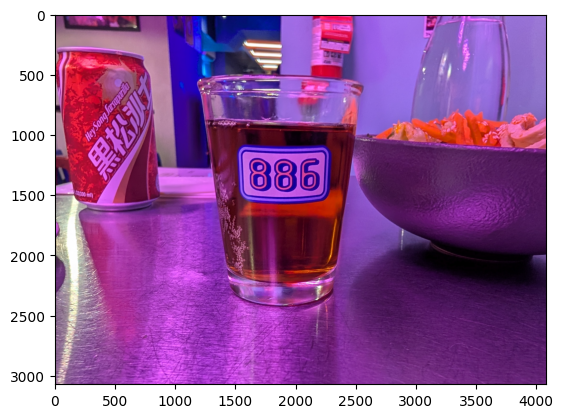

In [ ]:
plt.imshow(sdr)

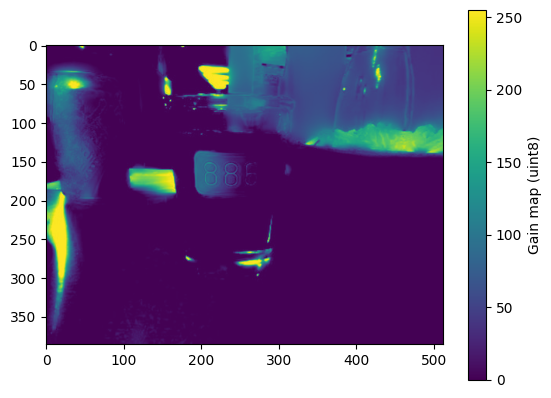

In [ ]:
plt.imshow(gain)
plt.colorbar(label="Gain map (uint8)", orientation="vertical")

In [ ]:
import subprocess, json, tempfile, os
# import numpy as np

with tempfile.NamedTemporaryFile(suffix=".jpg", delete=False) as t:
    t.write(gm_bytes)
    tmp = t.name
try:
    meta = json.loads(subprocess.run(
        ["exiftool", "-j", "-n", "-xmp-hdrgm:all", tmp],
        capture_output=True, check=True).stdout)[0]
finally:
    os.remove(tmp)
print(meta)

{'SourceFile': '/tmp/tmpdswr3q99.jpg', 'Version': 1.0, 'GainMapMin': 0.0, 'GainMapMax': 1.315908, 'HDRCapacityMin': 0.0, 'HDRCapacityMax': 1.315908, 'OffsetSDR': 0.0, 'OffsetHDR': 0.0}


In [ ]:
# import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

gmin  = np.asarray(meta.get("GainMapMin", 0.0), dtype=np.float32)
gmax  = np.asarray(meta["GainMapMax"],          dtype=np.float32)
gamma = np.asarray(meta.get("Gamma", 1.0),      dtype=np.float32)

g = gain.astype(np.float32) / 255.0
log2_gain = gmin + (gmax - gmin) * g ** (1.0 / gamma)   # stops; broadcasts if params are per-channel
linear_gain = 2.0 ** log2_gain

lim = max(abs(log2_gain.min()), abs(log2_gain.max()))

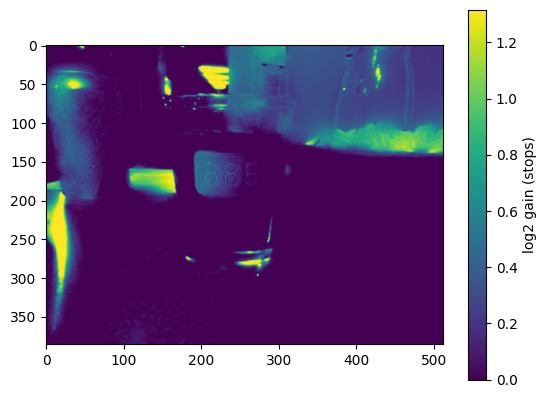

In [ ]:
# Display log2 gain
plt.imshow(log2_gain)
plt.colorbar(label="log2 gain (stops)")

In [ ]:
gainmap_path = "gainmap.jpg"

with open(gainmap_path, "wb") as f:
    f.write(gm_bytes)